# Plummer銀河とChandrasekhar動力学的摩擦
## 質量比1:10のminor mergerを模した最小モデル

このNotebookでは、銀河相互作用の発展課題として、Chandrasekharの動力学的摩擦による衛星銀河の軌道減衰を計算します。

モデルは次のように単純化します。

- host galaxy：原点に固定したPlummer球
- satellite galaxy：質量比 $M_{\rm sat}/M_{\rm host}=0.1$ の移動するPlummerポテンシャル
- satelliteの軌道：hostの重力とChandrasekhar動力学的摩擦で時間発展
- satelliteの恒星：質量ゼロのテスト粒子
- 時間積分：4次Runge--Kutta法（RK4）

これは自己無撞着なN体計算ではなく、**動力学的摩擦が衛星銀河の軌道を減衰させることを見るための半解析的な教材モデル**です。

## 1. 単位と標準パラメータ

単位は kpc, Gyr, $M_\odot$ を使います。

標準モデルでは

- $M_{\rm host}=10^{11}M_\odot$
- $M_{\rm sat}=10^{10}M_\odot$
- $a_{\rm host}=3$ kpc
- $a_{\rm sat}=1.5$ kpc
- 初期軌道半径 $R_0=20$ kpc

とします。

Coulomb logarithm は簡単な代表値として

$$
\ln\Lambda=\ln\left(1+\frac{M_{\rm host}}{M_{\rm sat}}\right)
$$

を使います。

In [1]:
from math import erf
import numpy as np
import matplotlib.pyplot as plt

KM_S_TO_KPC_GYR = 1.0227121650537077
G = 4.30091e-6 * KM_S_TO_KPC_GYR**2

M_HOST = 1.0e11
A_HOST = 3.0
M_SAT = 1.0e10
A_SAT = 1.5

R0 = 20.0
DT = 0.001
T_END = 1.50
LN_LAMBDA = np.log1p(M_HOST / M_SAT)

N_TRACER = 500
RD_SAT = 1.0
RMAX_SAT = 4.0
SPIN_SAT = +1
RANDOM_SEED = 42
SNAPSHOT_TIMES = [0.0, 0.5, 1.0, 1.5]

BLUE = "#0072B2"
VERMILLION = "#D55E00"
BLACK = "#000000"
GRAY = "#777777"

print(f"Mass ratio = {M_SAT / M_HOST:.2f}")
print(f"ln Lambda = {LN_LAMBDA:.3f}")

Mass ratio = 0.10
ln Lambda = 2.398


## 2. Plummerモデル

Plummerポテンシャルは

$$
\Phi(r)=-\frac{GM}{\sqrt{r^2+a^2}}
$$

で、加速度は

$$
\boldsymbol a
=
-GM\frac{\boldsymbol r}{(r^2+a^2)^{3/2}}
$$

です。

hostの密度は

$$
\rho(r)=
\frac{3M_{\rm host}}{4\pi a_{\rm host}^3}
\left(1+\frac{r^2}{a_{\rm host}^2}\right)^{-5/2},
$$

等方Plummer球の1次元速度分散は

$$
\sigma^2(r)=
\frac{GM_{\rm host}}{6a_{\rm host}}
\left(1+\frac{r^2}{a_{\rm host}^2}\right)^{-1/2}
$$

です。これらをChandrasekhar公式に使います。

In [2]:
def plummer_acceleration(pos, center, mass, a):
    dr = pos - center
    r2 = np.sum(dr * dr, axis=-1)
    return -G * mass * dr / (r2 + a * a)[..., None]**1.5

def circular_speed_plummer(radius, mass, a):
    return np.sqrt(G * mass * radius**2 / (radius**2 + a**2)**1.5)

def host_density(radius):
    return 3.0 * M_HOST / (4.0 * np.pi * A_HOST**3) * (1.0 + (radius / A_HOST)**2)**(-2.5)

def host_velocity_dispersion(radius):
    sigma2 = G * M_HOST / (6.0 * A_HOST) * (1.0 + (radius / A_HOST)**2)**(-0.5)
    return np.sqrt(sigma2)

## 3. Chandrasekhar動力学的摩擦

局所的な背景速度分布をMaxwell分布とみなすと、衛星銀河に働く加速度を

$$
\boldsymbol a_{\rm df}
=
-4\pi G^2 M_{\rm sat}\rho\ln\Lambda
\left[
\operatorname{erf}(X)
-\frac{2X}{\sqrt{\pi}}e^{-X^2}
\right]
\frac{\boldsymbol v}{v^3},
$$

$$
X=\frac{v}{\sqrt{2}\sigma}
$$

と書けます。

摩擦力は速度と逆向きなので、衛星銀河は軌道エネルギーと角運動量を失います。

> **注意**  
> この公式は一様・等方的な背景などを仮定して導かれた近似式です。Plummer球中のminor mergerに適用する本モデルは、動力学的摩擦の効果を理解するための半解析的な近似です。

In [3]:
def dynamical_friction_acceleration(pos, vel):
    radius = np.linalg.norm(pos)
    speed = np.linalg.norm(vel)

    if speed == 0.0:
        return np.zeros(2)

    rho = host_density(radius)
    sigma = host_velocity_dispersion(radius)
    x = speed / (np.sqrt(2.0) * sigma)
    velocity_factor = erf(x) - 2.0 * x / np.sqrt(np.pi) * np.exp(-x * x)

    prefactor = -4.0 * np.pi * G**2 * M_SAT * rho * LN_LAMBDA * velocity_factor
    return prefactor * vel / speed**3

## 4. RK4で衛星銀河の中心を積分する

まずテスト粒子を入れず、衛星銀河の中心軌道だけを計算します。

比較のため、

1. 動力学的摩擦なし
2. 動力学的摩擦あり

の2つを同じ初期条件から積分します。初期速度にはhostのPlummerポテンシャル中の円運動速度を使います。

In [4]:
def center_rhs(state, use_friction):
    pos = state[0:2]
    vel = state[2:4]
    acc = plummer_acceleration(pos[None, :], np.zeros(2), M_HOST, A_HOST)[0]

    if use_friction:
        acc += dynamical_friction_acceleration(pos, vel)

    return np.concatenate((vel, acc))

def rk4_center_step(state, dt, use_friction):
    k1 = center_rhs(state, use_friction)
    k2 = center_rhs(state + 0.5 * dt * k1, use_friction)
    k3 = center_rhs(state + 0.5 * dt * k2, use_friction)
    k4 = center_rhs(state + dt * k3, use_friction)
    return state + dt * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0

def integrate_center(use_friction):
    vc0 = circular_speed_plummer(R0, M_HOST, A_HOST)
    state = np.array([R0, 0.0, 0.0, vc0])

    n_steps = int(round(T_END / DT))
    times = np.arange(n_steps + 1) * DT
    history = np.empty((n_steps + 1, 4))
    radius = np.empty(n_steps + 1)
    energy = np.empty(n_steps + 1)
    angular_momentum = np.empty(n_steps + 1)

    for step in range(n_steps + 1):
        pos = state[0:2]
        vel = state[2:4]
        r = np.linalg.norm(pos)

        history[step] = state
        radius[step] = r
        energy[step] = 0.5 * np.dot(vel, vel) - G * M_HOST / np.sqrt(r * r + A_HOST**2)
        angular_momentum[step] = pos[0] * vel[1] - pos[1] * vel[0]

        if step < n_steps:
            state = rk4_center_step(state, DT, use_friction)

    return times, history, radius, energy, angular_momentum

times, history_no_df, radius_no_df, energy_no_df, angular_momentum_no_df = integrate_center(False)
_, history_with_df, radius_with_df, energy_with_df, angular_momentum_with_df = integrate_center(True)

print(f"Initial circular speed = {history_no_df[0, 3] / KM_S_TO_KPC_GYR:.1f} km/s")
print(f"Final radius without friction = {radius_no_df[-1]:.3f} kpc")
print(f"Final radius with friction = {radius_with_df[-1]:.3f} kpc")

Initial circular speed = 144.2 km/s
Final radius without friction = 20.000 kpc
Final radius with friction = 7.798 kpc


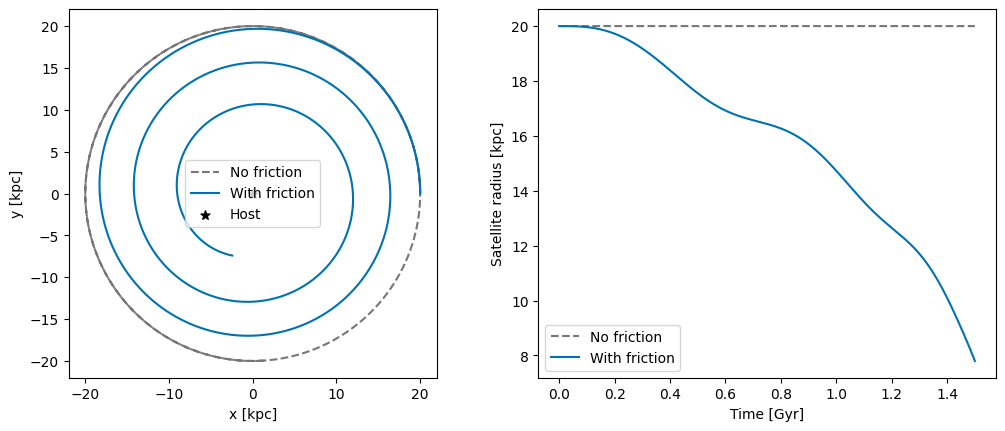

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.2), constrained_layout=True)

axes[0].plot(history_no_df[:, 0], history_no_df[:, 1], ls="--", c=GRAY, label="No friction")
axes[0].plot(history_with_df[:, 0], history_with_df[:, 1], c=BLUE, label="With friction")
axes[0].scatter(0.0, 0.0, s=45.0, c=BLACK, marker="*", label="Host")
axes[0].set_xlabel("x [kpc]")
axes[0].set_ylabel("y [kpc]")
axes[0].set_aspect("equal")
axes[0].legend()

axes[1].plot(times, radius_no_df, ls="--", c=GRAY, label="No friction")
axes[1].plot(times, radius_with_df, c=BLUE, label="With friction")
axes[1].set_xlabel("Time [Gyr]")
axes[1].set_ylabel("Satellite radius [kpc]")
axes[1].legend()

plt.show()

## 5. エネルギーと角運動量を見る

摩擦なしでは、軌道エネルギーと角運動量が保存されます。

摩擦ありでは、これらは保存されません。これは数値誤差ではなく、Chandrasekhar摩擦によって衛星銀河から背景系へエネルギーと角運動量が移るためです。

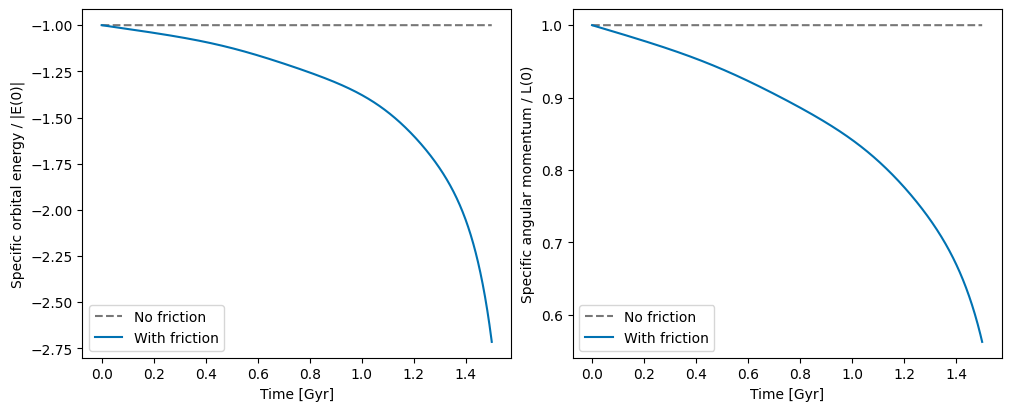

No-friction max relative energy error = 6.421e-12
No-friction max relative angular-momentum error = 3.355e-12


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.0, 4.0), constrained_layout=True)

axes[0].plot(times, energy_no_df / abs(energy_no_df[0]), ls="--", c=GRAY, label="No friction")
axes[0].plot(times, energy_with_df / abs(energy_with_df[0]), c=BLUE, label="With friction")
axes[0].set_xlabel("Time [Gyr]")
axes[0].set_ylabel("Specific orbital energy / |E(0)|")
axes[0].legend()

axes[1].plot(times, angular_momentum_no_df / angular_momentum_no_df[0], ls="--", c=GRAY, label="No friction")
axes[1].plot(times, angular_momentum_with_df / angular_momentum_with_df[0], c=BLUE, label="With friction")
axes[1].set_xlabel("Time [Gyr]")
axes[1].set_ylabel("Specific angular momentum / L(0)")
axes[1].legend()

plt.show()

energy_error_no_df = np.max(np.abs((energy_no_df - energy_no_df[0]) / energy_no_df[0]))
angular_momentum_error_no_df = np.max(np.abs((angular_momentum_no_df - angular_momentum_no_df[0]) / angular_momentum_no_df[0]))

print(f"No-friction max relative energy error = {energy_error_no_df:.3e}")
print(f"No-friction max relative angular-momentum error = {angular_momentum_error_no_df:.3e}")

## 6. 衛星銀河にテスト粒子を加える

次に、衛星銀河のPlummerポテンシャルの周囲に質量ゼロの恒星円盤を置きます。

粒子の半径分布には

$$
p(R)\propto R\exp(-R/R_d)
$$

を使い、**台形則でCDFを作り、線形補間で逆変換**します。

テスト粒子はhostとsatelliteの両方のPlummerポテンシャルを感じます。ただし、テスト粒子自身は重力場を作りません。

In [7]:
def sample_exponential_disk(n, rd, rmax, rng):
    r_grid = np.linspace(0.0, rmax, 4097)
    pdf = r_grid * np.exp(-r_grid / rd)

    cdf = np.zeros_like(r_grid)
    dr = np.diff(r_grid)
    cdf[1:] = np.cumsum(0.5 * (pdf[:-1] + pdf[1:]) * dr)
    cdf /= cdf[-1]

    radius = np.interp(rng.random(n), cdf, r_grid)
    phi = 2.0 * np.pi * rng.random(n)
    pos = np.column_stack((radius * np.cos(phi), radius * np.sin(phi)))
    return pos, radius, phi

def make_initial_state():
    rng = np.random.default_rng(RANDOM_SEED)

    sat_pos = np.array([R0, 0.0])
    sat_vel = np.array([0.0, circular_speed_plummer(R0, M_HOST, A_HOST)])

    rel_pos, radius, phi = sample_exponential_disk(N_TRACER, RD_SAT, RMAX_SAT, rng)
    vc = circular_speed_plummer(radius, M_SAT, A_SAT)
    tangent = np.column_stack((-np.sin(phi), np.cos(phi)))
    rel_vel = SPIN_SAT * vc[:, None] * tangent

    state = np.empty((1 + N_TRACER, 4))
    state[0, 0:2], state[0, 2:4] = sat_pos, sat_vel
    state[1:, 0:2] = sat_pos + rel_pos
    state[1:, 2:4] = sat_vel + rel_vel
    return state

In [8]:
def full_rhs(state):
    deriv = np.empty_like(state)
    deriv[:, 0:2] = state[:, 2:4]

    sat_pos = state[0, 0:2]
    sat_vel = state[0, 2:4]
    sat_acc = plummer_acceleration(sat_pos[None, :], np.zeros(2), M_HOST, A_HOST)[0]
    sat_acc += dynamical_friction_acceleration(sat_pos, sat_vel)
    deriv[0, 2:4] = sat_acc

    tracer_pos = state[1:, 0:2]
    tracer_acc = plummer_acceleration(tracer_pos, np.zeros(2), M_HOST, A_HOST)
    tracer_acc += plummer_acceleration(tracer_pos, sat_pos, M_SAT, A_SAT)
    deriv[1:, 2:4] = tracer_acc

    return deriv

def rk4_full_step(state, dt):
    k1 = full_rhs(state)
    k2 = full_rhs(state + 0.5 * dt * k1)
    k3 = full_rhs(state + 0.5 * dt * k2)
    k4 = full_rhs(state + dt * k3)
    return state + dt * (k1 + 2.0 * k2 + 2.0 * k3 + k4) / 6.0

def integrate_with_tracers():
    state = make_initial_state()
    n_steps = int(round(T_END / DT))
    save_steps = {int(round(t / DT)): t for t in SNAPSHOT_TIMES}
    snapshots = {}

    for step in range(n_steps + 1):
        if step in save_steps:
            snapshots[save_steps[step]] = state.copy()

        if step < n_steps:
            state = rk4_full_step(state, DT)

    return snapshots

snapshots = integrate_with_tracers()

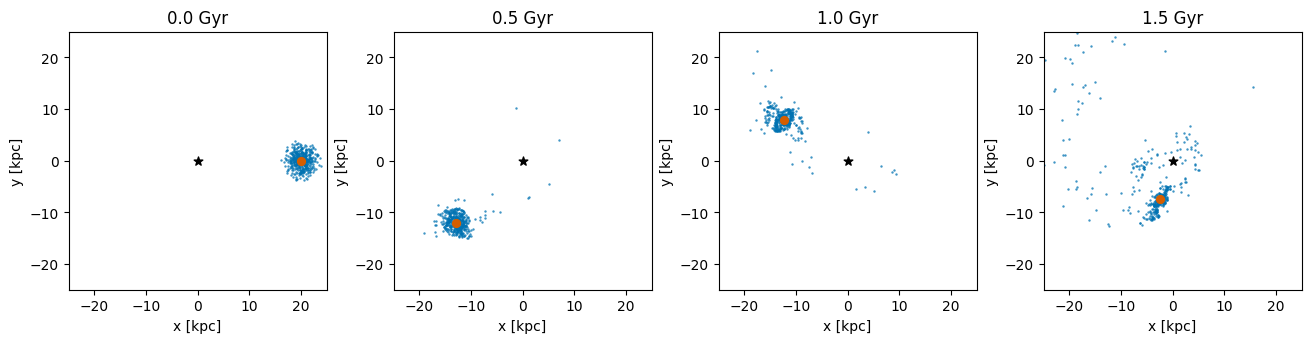

In [9]:
fig, axes = plt.subplots(1, len(SNAPSHOT_TIMES), figsize=(13.0, 3.4), constrained_layout=True)

for ax, time in zip(axes, SNAPSHOT_TIMES):
    state = snapshots[time]
    ax.scatter(state[1:, 0], state[1:, 1], s=3.0, c=BLUE, alpha=0.75, linewidths=0)
    ax.scatter(state[0, 0], state[0, 1], s=32.0, c=VERMILLION, marker="o", label="Satellite")
    ax.scatter(0.0, 0.0, s=42.0, c=BLACK, marker="*", label="Host")
    ax.set_title(f"{time:.1f} Gyr")
    ax.set_xlabel("x [kpc]")
    ax.set_ylabel("y [kpc]")
    ax.set_xlim(-25.0, 25.0)
    ax.set_ylim(-25.0, 25.0)
    ax.set_aspect("equal")

plt.show()

## 7. 数値実験

### 確認
`use_friction=False` の計算で、軌道エネルギーと角運動量が保存されることを確認してください。

### 応用
`M_SAT = 5e9`, `1e10`, `2e10` $M_\odot$ と変えて、軌道減衰の速さを比較してください。

### 応用
`LN_LAMBDA` を 1, 2, 3 と変えて、$R(t)$ を比較してください。

### 発展
衛星銀河の初期軌道速度を円運動速度の80%にして、離心した軌道から始めてください。動力学的摩擦による近日点・遠日点の変化を調べてください。

> **もう少し詳しく：Coulomb logarithm**  
> $\ln\Lambda$ は、重力散乱に寄与する最大・最小インパクトパラメータの比に関係する量です。実際の銀河では一定値とは限りません。本書では動力学的摩擦の基本的な効果を調べるため、簡単な代表値を使います。

## このモデルの限界

この計算ではhostを固定した滑らかなPlummer背景として扱います。そのため、実際のN体計算で形成される重力wakeを直接計算しているわけではありません。Chandrasekhar公式によって、その反作用を近似的に衛星銀河へ加えています。

また、

- hostの変形
- satelliteの質量損失に伴う $M_{\rm sat}$ の時間変化
- 自己無撞着なダークハロー応答
- 3次元構造

は扱っていません。

このNotebookの目的は、**動力学的摩擦によって衛星銀河の軌道半径・エネルギー・角運動量が減少することを、簡単な数値計算で確認すること**です。